# 04 Python项目实战之网络机器人

本章依据桌面讲义《第4章 - Python项目实战之网络机器人》整理。讲义封面也把这个主题称为“爬虫”：让程序按照规则获取网页，再从网页中提取、清洗和保存需要的数据。

上一章学习了通过 HTTP 调用大模型接口。本章继续使用 HTTP，但面对的主要结果变成了 **HTML 网页**。程序要把“供浏览器展示的页面”变成“可以继续分析的结构化数据”。

| 部分 | 讲义内容 | 学习目标 |
| --- | --- | --- |
| 网络机器人入门 | 工作流程、robots、Requests、网页结构 | 知道怎样获取页面，以及拿到的内容是什么 |
| 网页解析 | lxml、XPath | 从 HTML 中准确定位元素、文本和属性 |
| 网络机器人案例 | 高分电影 Top100、CSV | 把列表页、详情页与文件保存串起来 |
| 案例拓展 | 字符串处理、正则表达式 | 把年份、日期、时长等字段整理成统一格式 |

**阅读说明：**保留讲义的知识、案例、语法表和复习问题，重复展示页合并。讲义没有提供完整的电影采集源码或“仙逆人物志”资源文件；需要补齐的代码和练习素材会明确标为“补充”。图片直接嵌入笔记，可离线阅读。代码按说明复制到文件运行，不要把整篇笔记当成一个脚本一次执行。

## 一、网络机器人是什么

### 1. 概念与应用

网络机器人，也叫网络爬虫，是按照预设规则自动浏览并获取网络数据的程序或脚本。

它可以重复完成一些原本需要手工操作的工作：打开页面、寻找内容、复制信息、进入下一页、把结果整理到表格。

讲义列出的应用场景包括：

| 场景 | 主要用途 |
| --- | --- |
| 搜索引擎，如百度、Google | 发现网页、获取内容，为搜索索引提供资料 |
| 舆情监控 | 持续获取公开信息，观察相关话题的变化 |
| 商业分析、电商比价 | 获取商品与价格信息，进行比较 |
| AI 大模型训练语料 | 为数据集建设获取适用资料，之后还需清洗、筛选等处理 |

爬虫不一定需要 AI 模型。本章主要使用 Python 的网络、解析和文件处理能力；获取的数据将来可以用于数据分析或 AI 应用。

### 2. 讲义中的工作流程

```text
开始
  → 确认目标与访问规则
  → 发送 HTTP 请求
  → 解析结果，提取数据
  → 数据处理与清洗
  → 数据存储
结束
```

| 环节 | 输入 | 输出 |
| --- | --- | --- |
| 发送请求 | URL、请求头等 | HTTP 响应和页面内容 |
| 解析提取 | HTML 文档 | 标题、链接、日期、评分等原始字段 |
| 清洗 | 原始文本 | 类型明确、格式统一的数据 |
| 存储 | 字典或列表 | CSV 等文件 |

**数据清洗**是对原始数据进行处理、修正、转换和标准化，使其更加规范、准确。例如，把 `"(1994)"` 处理成年份 `1994`，把 `"2h 22m"` 转换成分钟数 `142`。

这些步骤不要混为一谈：请求成功不等于已经提取到数据；提取到文字也不等于这些文字已经能直接用于计算。

## 二、robots.txt：先看网站允许怎样访问

### 1. robots 协议是什么

robots 协议也称爬虫协议或爬虫规则。网站通常在根路径的 `robots.txt` 中声明针对不同爬虫的访问规则，例如：

- [TIOBE 的 robots.txt](https://www.tiobe.com/robots.txt)
- [TMDB 的 robots.txt](https://www.themoviedb.org/robots.txt)

讲义称它为“君子协议”：它主要依赖客户端主动遵守，不是用来代替账号权限和访问控制的技术措施。

**补充：**robots 允许访问，不等于授予数据的一切使用权。实际获取和使用数据还要结合网站条款、访问权限以及具体用途理解。本章只围绕课程案例学习公开页面的获取与解析。

### 2. 讲义中的完整规则示例

下面是课件用于说明语法的分组示例，不应当作所有网站当前都在使用的同一份规则：

```text
User-agent: *
Disallow: /wp-admin/
Allow: /wp-admin/admin-ajax.php
Sitemap: https://www.tiobe.com/sitemap_index.xml
Crawl-delay: 5

User-agent: Wandoujia Spider
Disallow: /

User-agent: Mediapartners-Google
Disallow: /subject_search
Disallow: /amazon_search
Disallow: /search
Disallow: /group/search
```

逐项解释：

| 指令 | 含义 |
| --- | --- |
| `User-agent: *` | 针对通用爬虫的规则组 |
| `Disallow: /wp-admin/` | 声明不允许访问此路径范围 |
| `Allow: /wp-admin/admin-ajax.php` | 声明允许访问这个更具体的路径 |
| `Sitemap: ...` | 指出网站地图的位置，帮助发现内容 |
| `Crawl-delay: 5` | 请求之间留出间隔的扩展约定，此例为 5 秒 |
| `User-agent: Wandoujia Spider` | 面向特定爬虫标识的规则组 |
| `Disallow: /` | 此规则组不允许抓取整个站点 |
| 多行 Disallow | 为同一组列出多个不允许访问的路径 |

robots 中的 `User-agent` 用于选择适用规则组；HTTP 请求头中的 `User-Agent` 用于说明客户端身份。两者有关联，但不是同一个文件里的同一种写法，也不是可靠的身份认证。

**补充：规则细节。**更具体的爬虫规则组、Allow 与 Disallow 的路径匹配，都需要按协议与解析器支持情况理解；不能把所有组简单拼成一份黑名单。`Crawl-delay` 并非所有爬虫都支持的统一标准字段，即使未写，也不能理解为可以无限频率访问。

### 3. 课程材料与当前网站的差别

课件里的规则和页面都是某个时点的资料，实际运行前需要重新查看。

整理本章时，TIOBE 的 robots 中保留了 `/wp-admin/` 限制，没有示例里的 `Crawl-delay: 5`。本文参考程序仍主动保留至少 5 秒间隔，这属于程序设置，不把它冒称为网站当前声明。

TMDB 当前 robots 明确限制了包括 OpenAI、GPTBot、ChatGPT-User 等在内的多种自动客户端。**本章没有自动抓取它的实时电影榜单或详情页。**课程中的电影界面与字段仍完整讲解，并配有离线教学 HTML，让解析、清洗、分页、去重和 CSV 保存可以实际运行。后面会区分讲义截图、离线样例和线上访问条件。

### 4. 本节复习

- robots.txt 通常放在哪里？网站根路径。
- `Disallow` 表示什么？该规则组不允许抓取的路径。
- `Allow` 表示什么？该规则组允许抓取的路径。
- `Sitemap` 是什么？网站地图地址。
- `Crawl-delay` 用于什么？约定访问间隔，但支持情况因客户端而异。
- 看到 robots 规则后做什么？确认自己适用的规则，再安排实际请求。

## 三、Requests 入门：获取 TIOBE 排行榜页面

### 1. 讲义任务

获取 TIOBE 编程语言排行榜页面。课件步骤为：

1. 查看目标网站的 robots.txt，明确访问规则。
2. 安装 Requests。
3. 编写 Python 程序，请求页面，获取返回内容。

页面地址：[TIOBE Index](https://www.tiobe.com/tiobe-index/)。

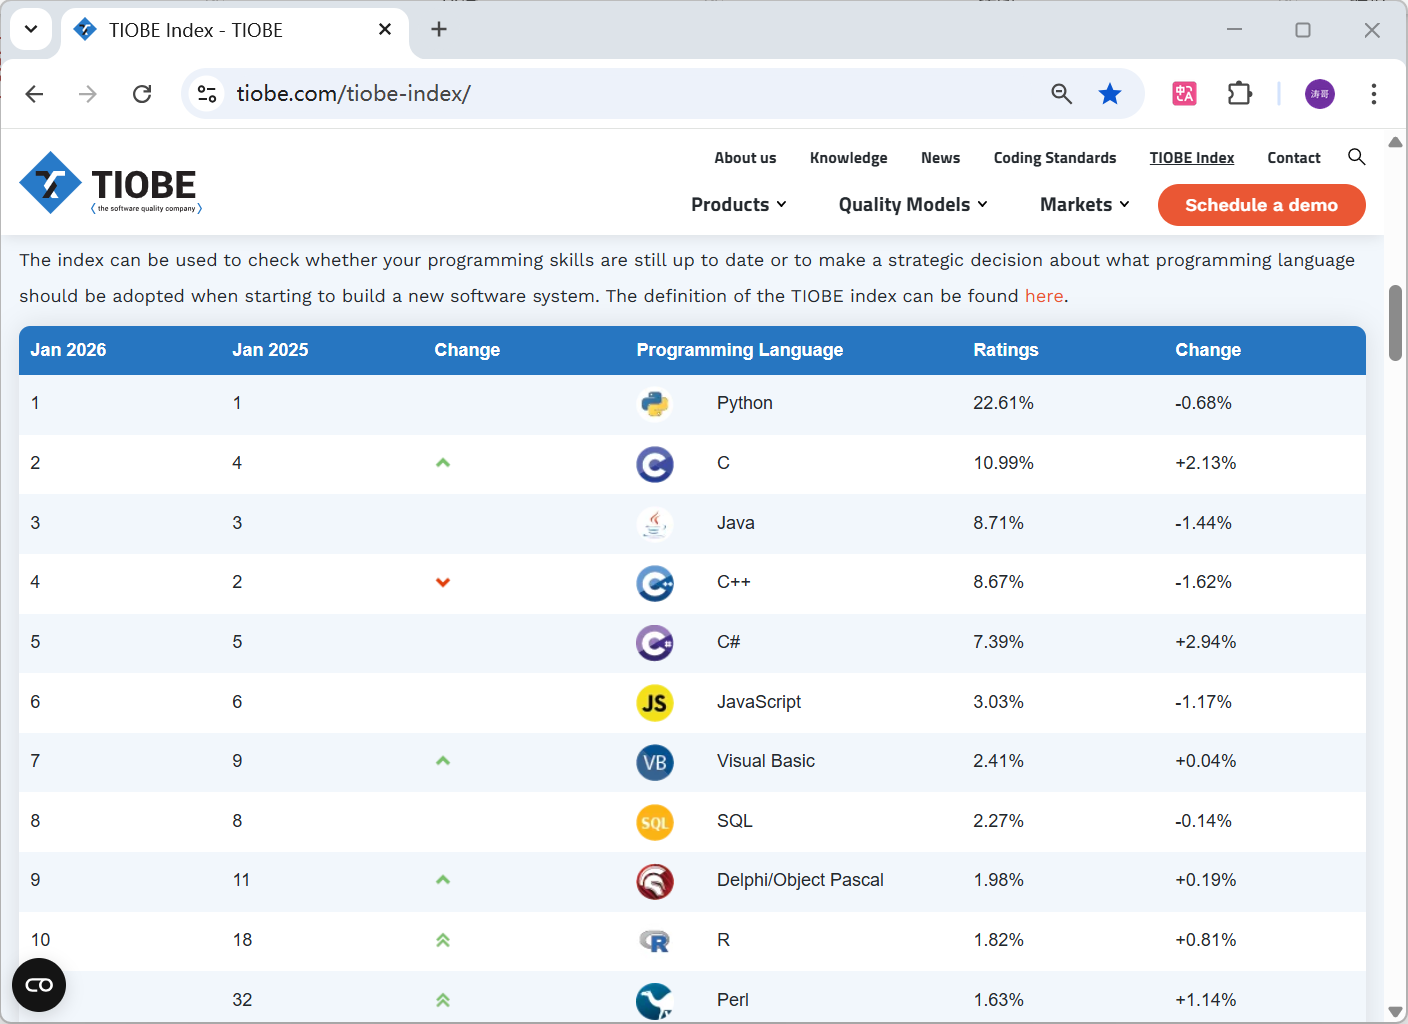

*讲义中的 TIOBE 榜单截图，展示的是课件当时的数据。*

**补充：**TIOBE 是编程语言流行程度的指标，不是“哪门语言最好”的判定，也不是各语言代码量排行榜。它按月变化，学习重点是怎样获取和解析表格，不是背下截图中的百分比。

### 2. Requests 是什么

Requests 是常用的 Python HTTP 客户端库，用 Python 发送请求、读取响应比较方便。

安装本章依赖：

```powershell
python -m venv .venv
.\.venv\Scripts\python.exe -m pip install requests lxml
```

`requests` 用于请求，`lxml` 用于解析网页，后面会继续使用。`csv`、`re`、`time`、`urllib` 等属于标准库，不需要单独安装。

### 3. 最小请求示例

> **补充：参考代码。**PPT 给出了任务和步骤，下面补成一个完整请求示例。运行前先完成上面的 robots 核对。

保存为 `request_demo.py`：

```python
from pathlib import Path
import requests

url = "https://www.tiobe.com/tiobe-index/"
headers = {"User-Agent": "OpenAI-EducationExample/1.0"}

response = requests.get(url, headers=headers, timeout=20)
response.raise_for_status()

print("状态码：", response.status_code)
print("内容类型：", response.headers.get("Content-Type"))
print("响应前 300 个字符：")
print(response.text[:300])

output = Path(__file__).resolve().parent / "resources" / "tiobe.html"
output.parent.mkdir(parents=True, exist_ok=True)
output.write_bytes(response.content)
print("HTML 已保存到：", output)
```

运行：

```powershell
.\.venv\Scripts\python.exe request_demo.py
```

| 写法 | 含义 |
| --- | --- |
| `requests.get(url, ...)` | 发出 GET 请求 |
| `headers` | 设置 HTTP 请求头 |
| `timeout=20` | 给连接与读取设置超时，避免无限等待 |
| `response.status_code` | HTTP 状态码 |
| `response.raise_for_status()` | 对 4xx、5xx 等失败响应抛出异常 |
| `response.text` | 按响应编码解码得到的字符串 |
| `response.content` | 原始响应字节 |
| `write_bytes(...)` | 把字节保存到本地文件 |

**补充：**Requests 的 timeout 不是整个任务绝对只能耗时 20 秒的总时限。它主要约束连接和读取等待。请求也可能因为网络错误、超时或服务器拒绝而失败；不要在这些情况下仍把错误页当成正常榜单。

当中文解码有问题时，应先核对响应头和 HTML 声明的编码。不能把任何网页都武断地设置成同一种编码。本例保存原始字节，后面让 HTML 解析器结合文档信息读取。

### 4. 获取到 HTML，为什么还不是排行榜数据

`response.text` 通常包含大量标签、样式和脚本。即使浏览器里看到漂亮的表格，程序拿到的也主要是 HTML 文档。

要得到可用的“排名、语言名、占比”，还需要：

```text
HTML 字节/文本 → 解析文档树 → 定位每一行 → 提取单元格 → 组织字典
```

**补充：Requests 不执行网页中的 JavaScript。**若某个网站在页面打开后才通过脚本加载数据，直接请求初始 HTML 可能看不到最终数据。这不是换一个 XPath 就必然能解决的问题，先确认返回内容里是否真的包含目标数据。

### 5. 本节复习

Requests 的作用是发送 HTTP 请求、取得响应。它负责获取页面，不负责自动把页面转换成电影或语言信息，也不会自动完成网页渲染、数据清洗和 CSV 保存。

## 四、网页结构：HTML、CSS、JavaScript

### 1. 三者分别负责什么

讲义用“结构、样式、行为”区分网页的三个常见组成部分：

| 技术 | 全称或名称 | 负责内容 | 例子 |
| --- | --- | --- | --- |
| HTML | HyperText Markup Language，超文本标记语言 | 页面元素和内容结构 | 标题、段落、链接、表格 |
| CSS | Cascading Style Sheets，层叠样式表 | 元素外观与布局 | 颜色、字号、粗细、位置 |
| JavaScript | 常写作 JS | 交互和动态行为 | 鼠标经过变色、按钮响应 |

**补充：**一个网页可以没有自己的 CSS 或 JavaScript，仍然能展示基本 HTML 内容。“三个部分”是对常见职责的划分，不是规定任何网页都必须同时包含三种代码。

讲义通过“仙逆人物志”页面展示三者配合后的效果：

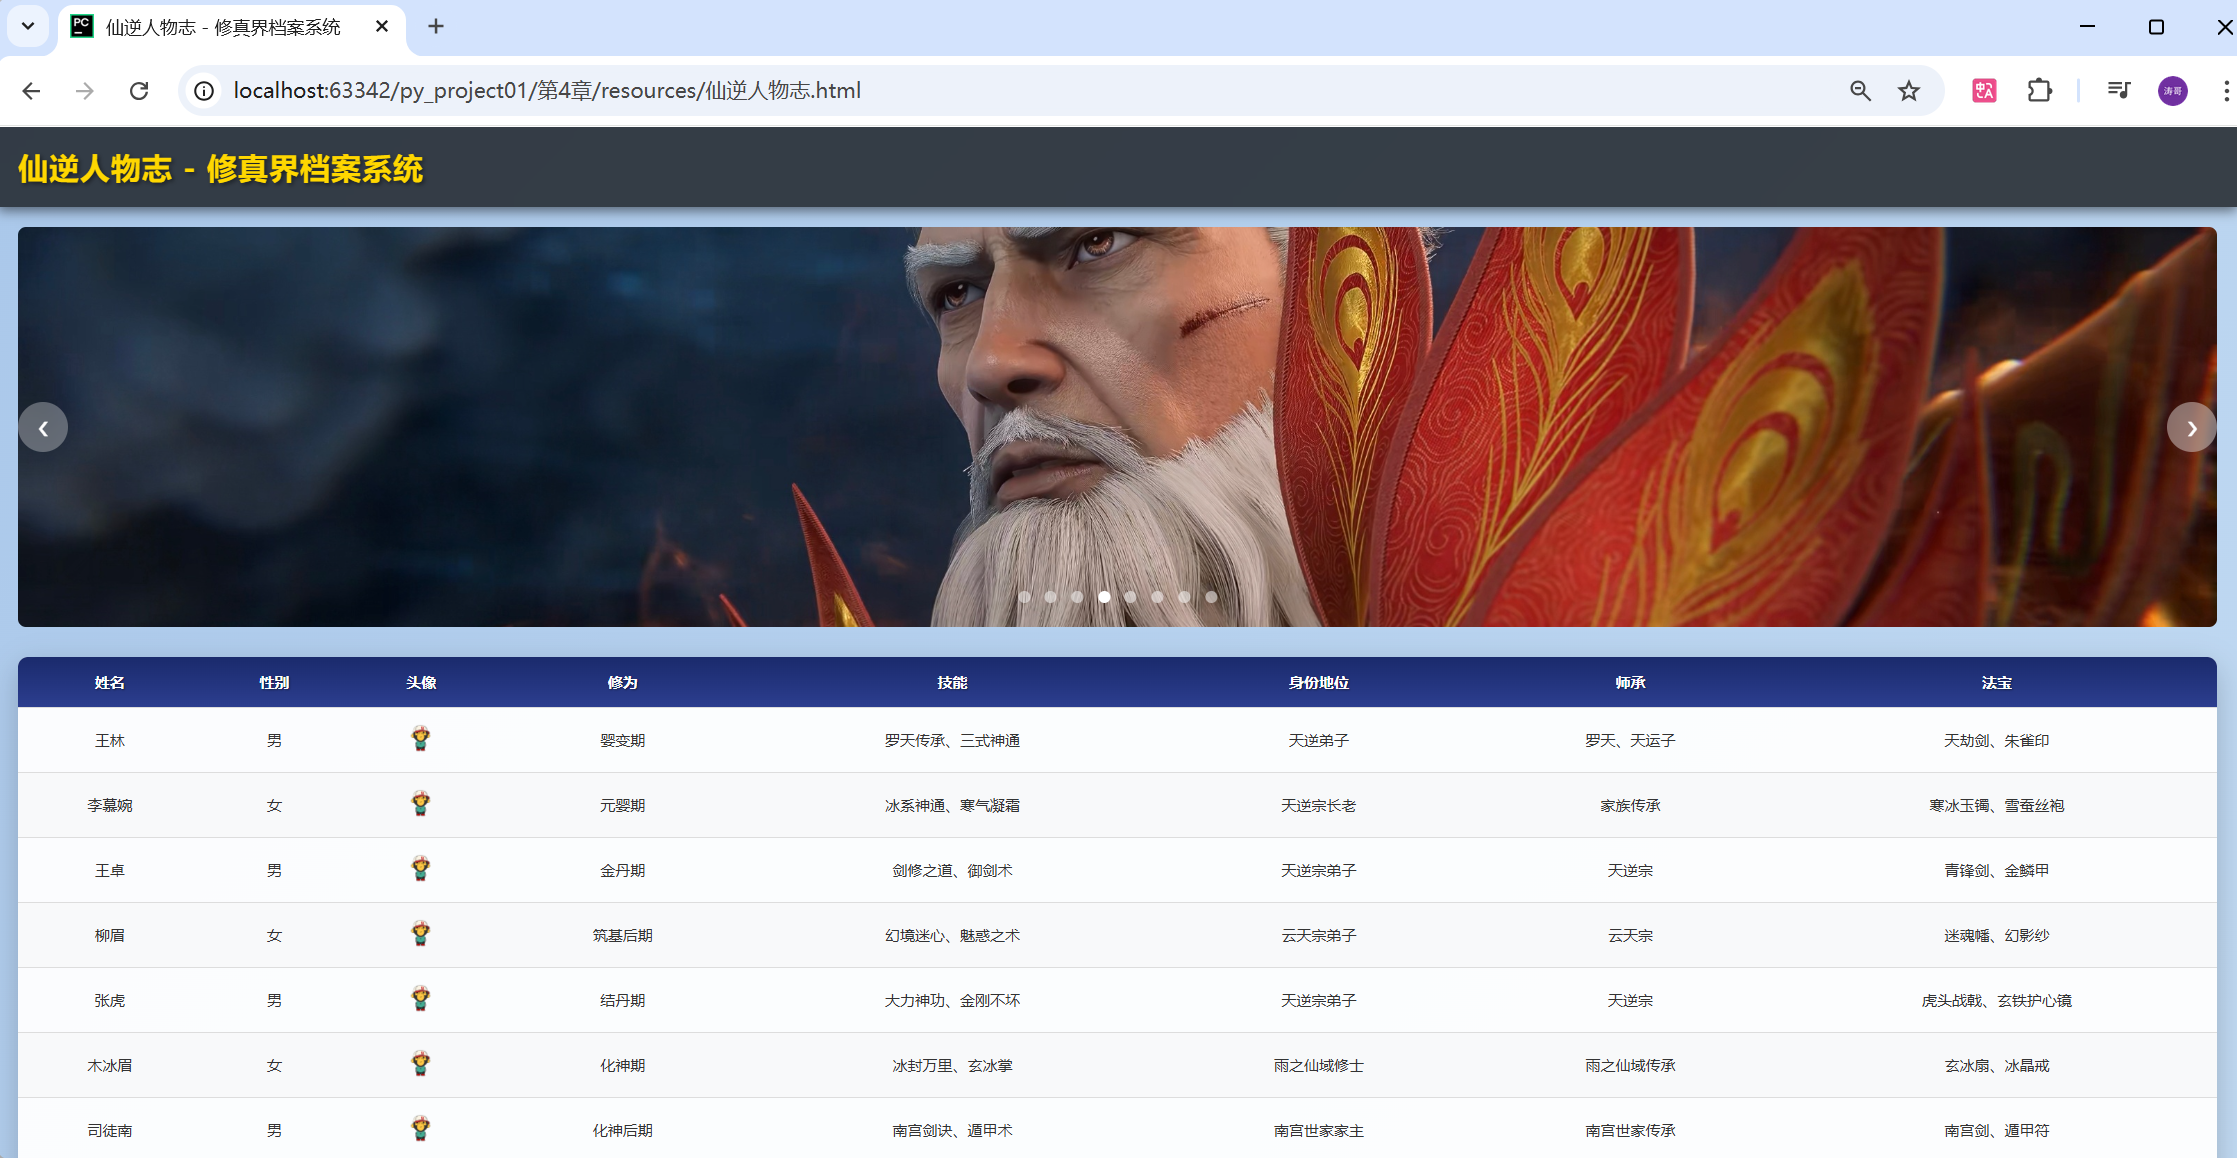

*讲义中的仙逆人物志页面：标题、图片、人物表格构成内容，颜色和布局体现样式。*

对爬虫而言，需要重点识别 HTML 的结构，理解哪些数据是初始 HTML 中已有的，哪些由 JavaScript 后续生成。

### 2. 在浏览器中观察结构

**补充：操作方法。**在浏览器中打开练习 HTML，按 `F12` 打开开发者工具，选中页面元素，观察对应标签、class 和属性。这样可以把“屏幕上的名字”与“HTML 中存放名字的节点”联系起来。

浏览器 Elements 面板显示的是当前 DOM，可能已经被脚本修改，也可能被浏览器补上了某些结构。它不一定与 Requests 拿到的原始文档逐字一致；解析时应以实际响应内容为准。

### 3. 讲义完整示例：标题样式与鼠标变色

保存为 `page_demo.html`，用浏览器打开：

```html
<html lang="zh-CN">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>仙逆人物志 - 修真世界</title>
  <style>
    .title {
      font-size: 30px;
      font-weight: bold;
      color: #ffd700;
      transition: color 0.3s ease; /* 添加颜色过渡效果 */
    }
  </style>
</head>
<body>
  <div class="content">
    <nav class="top-nav">
      <h1 class="title">仙逆人物志 - 修真界档案系统</h1>
    </nav>
    <footer class="footer">
      <div class="container">
        <p>© 2026 仙逆人物志 - <span>修真界档案系统</span></p>
        <p>探索修真世界的奥秘，记录修仙路上的传奇</p>
      </div>
    </footer>
  </div>
  <script>
      document.title = "仙逆人物志 - 修真世界";
      const titleElement = document.querySelector('.title'); // 获取标题元素
      titleElement.addEventListener('mouseenter', function() { // 鼠标进入标题时改变颜色
        this.style.color = '#ff6600'; // 改为橙红色
      });
      titleElement.addEventListener('mouseleave', function() { // 鼠标离开标题时恢复原色
        this.style.color = '#ffd700'; // 恢复金黄色
      });
  </script>
</body>
</html>
```

代码中三种职责分别是：

- HTML 的 `h1` 写出“仙逆人物志 - 修真界档案系统”，footer 写出页脚内容。
- CSS 的 `.title` 选择 class 为 title 的元素，设置字号 30px、粗体、金黄色。
- `transition: color 0.3s ease` 让颜色变化带过渡效果。
- JavaScript 用 `document.querySelector('.title')` 找到标题。
- `mouseenter` 在鼠标进入时把颜色改成橙红色。
- `mouseleave` 在鼠标移出时恢复金黄色。
- `document.title` 设置浏览器标签页上的标题。

`.title` 中的点号属于 CSS 选择器写法。它与后面 XPath 里的点号不是同一套语法，不能混着使用。

**补充：**创建新的 HTML 文档时，通常在最前面写 `<!doctype html>`，声明使用现代 HTML 的标准模式。课件示例没有写这一行，正文保留它的示例内容，实际练习可补在最前面。

### 4. HTML 的含义

**超文本**：不只有普通文字，还可以表达链接、图片、音频、视频等内容。

**标记语言**：通过标签表示内容的含义和结构。比如：

| 标签 | 常见作用 |
| --- | --- |
| `<h1>` | 一级标题 |
| `<p>` | 段落 |
| `<a>` | 超链接 |
| `<img>` | 图片 |
| `<video>` | 视频 |
| `<div>` | 通用内容容器 |
| `<table>` | 表格 |

浏览器解析 HTML 后构造页面。HTML 本身不是像 Python 一样的通用编程语言，不要把“浏览器展示 HTML”理解为执行一套 Python 风格的语句。

### 5. 简单页面示例

下面对应课件的简化 HTML，修正了“简介”应为“简洁”的用词：

```html
<html lang="zh-CN">
<head>
  <meta charset="UTF-8">
  <title>仙逆人物志 - 修真世界</title>
</head>
<body>
  <h1>Python</h1>
  <p>一门简洁、快速、易用的编程语言。</p>
  <a href="https://www.itcast.cn">传智教育-黑马程序员</a>
</body>
</html>
```

其中 `head` 保存编码、标题等元信息，`body` 保存主要页面内容。`title` 显示在浏览器标签页上；`h1` 显示在页面正文中，两者作用不同。

### 6. 标签、内容与属性

以链接为例：

```html
<a href="https://www.itcast.cn">传智教育-黑马程序员</a>
```

- `<a ...>` 是开始标签。
- `</a>` 是结束标签。
- “传智教育-黑马程序员”是元素内部文本。
- `href` 是属性名，属性值是目标地址。

后面提取链接时，“显示文字”和“href 地址”要分别获取。它们可以完全不同，不能看到文字像一个网址就认定那一定是链接目标。

**补充：**并不是所有 HTML 标签都要写结束标签，例如 `img`、`meta` 属于空元素。标签可以嵌套，嵌套关系形成文档树，是 XPath 查找的基础。

本笔记中的 `<a href="...">` 出现在 HTML 教学代码块中，用于讲解网页链接；它不是笔记的页内导航或手写锚点。

## 五、lxml 入门：把 HTML 解析成可查询的树

### 1. 网页解析是什么

网页解析是从原始 HTML 文档提取所需信息的过程。例如，面对上面的简单页面，希望得到：

| 目标 | 提取结果 |
| --- | --- |
| 网页标题 | 仙逆人物志 - 修真世界 |
| 一级标题 | Python |
| 段落 | 一门简洁、快速、易用的编程语言。 |
| 链接文字 | 传智教育-黑马程序员 |
| 链接地址 | https://www.itcast.cn |

lxml 是用于解析 HTML/XML 的库，支持 XPath 查询。本章使用：

```python
from lxml import html
```

安装：

```powershell
.\.venv\Scripts\python.exe -m pip install lxml
```

### 2. 补充：先运行一个自包含的小例子

```python
from lxml import html

content = """
<html><head><title>仙逆人物志 - 修真世界</title></head>
<body>
  <h1>Python</h1>
  <p>一门简洁、快速、易用的编程语言。</p>
  <a href="https://www.itcast.cn">传智教育-黑马程序员</a>
</body></html>
"""
doc = html.fromstring(content)

print(doc.xpath("/html/head/title/text()"))
print(doc.xpath("//h1/text()"))
print(doc.xpath("//p/text()"))
print(doc.xpath("//a/text()"))
print(doc.xpath("//a/@href"))
```

对应输出：

```text
['仙逆人物志 - 修真世界']
['Python']
['一门简洁、快速、易用的编程语言。']
['传智教育-黑马程序员']
['https://www.itcast.cn']
```

`html.fromstring(...)` 把文本或字节解析为文档元素。`doc.xpath(...)` 执行 XPath 表达式。

这些例子得到的是列表，查询不到时通常是空列表。因此不能在没有检查的情况下认为 `result[0]` 一定存在。XPath 也可以返回字符串、数字、布尔值，例如后面会用到的 `string(...)`，并非任何 XPath 都只能返回列表。

### 3. 课件示例：读取人物表格

讲义代码如下：

```python
from lxml import html

# 加载html文件
with open("resources/仙逆人物志.html", "r", encoding="utf-8") as f:
    html_content = f.read()

    # 解析网页内容
    doc = html.fromstring(html_content)
    th_list = doc.xpath("//table/thead/tr[1]/th/text()")
    print(th_list)

    td_list = doc.xpath("//table/tbody/tr[1]/td/text()")
    print(td_list)
```

两条表达式分别取：

- 表头第一行的 th 文本。
- 表体第一行的 td 直接文本。

其中 `tr[1]` 表示第 1 行，不是 Python 中的第 2 项。XPath 的位置编号从 1 开始。

### 4. 补充：准备可运行的表格文件

PPT 中出现了完整“仙逆人物志”页面截图，但没有附带对应 HTML 资源。为了运行上面的代码，可以在项目的 resources 目录中新建 `仙逆人物志.html`，使用以下教学表格。它保留截图的列结构和第一行主要文字，不是对整张网页源文件的逐字还原。

```html
<!doctype html>
<html lang="zh-CN">
<head><meta charset="UTF-8"><title>仙逆人物志</title></head>
<body>
<table>
  <thead>
    <tr>
      <th>姓名</th><th>性别</th><th>头像</th><th>修为</th>
      <th>技能</th><th>身份地位</th><th>师承</th><th>法宝</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>王林</td><td>男</td><td><span>👤</span></td><td>婴变期</td>
      <td>罗天传承、三式神通</td><td>天逆弟子</td>
      <td>罗天、天运子</td><td>天劫剑、朱雀印</td>
    </tr>
  </tbody>
</table>
</body>
</html>
```

从项目目录运行课件代码，`resources/...` 才会指向预期位置；相对路径仍然基于当前工作目录，和上一章的规则一致。

### 5. text() 与嵌套标签的区别

在上面的表格中，头像的文字放在 `span` 里，不是 td 的直接文本节点。因此：

```python
from lxml import html

doc = html.fromstring("<table><tr><td><span>头像</span></td><td>王林</td></tr></table>")
print(doc.xpath("//td/text()"))
print([cell.text_content() for cell in doc.xpath("//td")])
```

输出：

```text
['王林']
['头像', '王林']
```

如果把第一条查询的结果直接与表头一一对应，就会错位。**补充：更稳妥的表格处理方式是先取每一个 td，再在单元格内部提取全部文本。**

```python
from lxml import html

with open("resources/仙逆人物志.html", encoding="utf-8") as f:
    doc = html.fromstring(f.read())

headers = [" ".join(cell.text_content().split())
           for cell in doc.xpath("//table/thead/tr[1]/th")]
for row in doc.xpath("//table/tbody/tr"):
    values = [" ".join(cell.text_content().split()) for cell in row.xpath("./td")]
    if len(values) != len(headers):
        raise ValueError("表头和数据列数不一致，请检查页面结构")
    print(dict(zip(headers, values)))
```

这样每个单元格都保留自己的位置。这里用到 `split()` 再 `" ".join(...)`，是把多余空白整理成单个空格，属于简单数据清洗。

## 六、XPath：准确定位元素、属性和文本

### 1. XPath 的用途

XPath 是在 HTML/XML 文档中定位节点的查询语言。它利用节点之间的父子关系、位置和属性，从一棵文档树中选出目标。

课件的练习结构如下，已把“简介”修正为“简洁”：

```html
<html lang="zh-CN">
<head>
  <meta charset="UTF-8">
  <title>仙逆人物志 - 修真世界</title>
</head>
<body>
  <div>
    <h1>Python</h1>
    <p>一门简洁、快速、易用的编程语言。</p>
    <p>人生苦短，我用Python。</p>
    <p color="red">AI大模型开发、AI智能应用开发。</p>
    <a href="https://www.itcast.cn">黑马程序员</a>
  </div>
</body>
</html>
```

**补充：**这里保留 `color="red"` 是为了练习“按属性筛选”。普通 p 元素上的这个属性不会自动等同于 CSS 的红色文本效果；实际控制颜色通常写 CSS。

### 2. 讲义语法表，逐项说明

| 表达式 | 含义 | 课件例子 |
| --- | --- | --- |
| `/` | 路径中选择直接子元素；开头的 / 表示从文档根开始 | `/html/body/div/h1` |
| `//` | 简写为向后代范围中查找，开头使用时可在整个文档查找 | `//h1` |
| `.` | 当前上下文节点 | `./a`、`.//a` |
| `[n]` | 按当前选择步骤中的位置筛选第 n 项，编号从 1 开始 | `//p[2]` |
| `[last()]` | 选择当前步骤中的最后一项 | `//p[last()]` |
| `[@attr]` | 选择带有指定属性的元素 | `//p[@color]` |
| `[@attr='value']` | 选择属性值等于指定值的元素 | `//p[@color='red']` |
| `*` | 匹配任意元素名称 | `//body/div/*` |
| `@*` | 选择元素的所有属性值 | `//body/div/a/@*` |
| `text()` | 选择直接文本节点 | `//div/p/text()` |

表中 `@attr` 里的 attr 是占位写法，要换成真实属性名。例如 `@href` 是链接目标地址，`@class` 是 class 属性，`@src` 常用于图片源地址。

### 3. / 与 // 的区别

对于上面的结构：

```text
/html/body/div/h1
```

逐层找 html → body → div → h1，必须符合这条父子链。

```text
//h1
```

在文档中查找 h1，不必先写出完整父子链。

下面两个表达式也不一样：

```text
//div/a       找 div 的直接子元素 a
//div//a      找 div 后代范围中的 a，可以隔着 span 等中间层
```

**补充：**绝对路径很直观，但页面中多加一个布局容器时可能失效。实际项目通常结合稳定属性和相对位置定位，不应认为路径越长就越可靠。

### 4. . 与相对查询

循环处理表格行或人物卡片时，查询应从当前那一行或卡片出发：

```python
from lxml import html

doc = html.fromstring("""
<div>
  <section><a href="/a">甲</a></section>
  <section><a href="/b">乙</a></section>
</div>
""")
for section in doc.xpath("//section"):
    print(section.xpath("./a/text()"))
```

输出：

```text
['甲']
['乙']
```

`./a` 取当前节点的直接子元素；`.//a` 取当前节点后代中的 a。

如果在循环里写 `//a`，查询可能回到整棵文档的范围，导致每次都提取到同一批全局链接。这是“所有行数据都一样”的常见原因。

### 5. 位置筛选：从 1 开始，但不总是全局第 n 个

对于只有一个 div 的课件示例：

| 查询 | 结果含义 |
| --- | --- |
| `//p[2]` | div 下第 2 个 p，即“人生苦短，我用Python。” |
| `//p[last()]` | div 下最后一个 p，即“AI大模型开发、AI智能应用开发。” |

**补充：有多个父节点时，要区分局部位置和全局位置。**

```python
from lxml import html

doc = html.fromstring("""
<body>
  <div><p>A1</p><p>A2</p></div>
  <div><p>B1</p><p>B2</p></div>
</body>
""")
print(doc.xpath("//p[2]/text()"))
print(doc.xpath("(//p)[2]/text()"))
```

输出：

```text
['A2', 'B2']
['A2']
```

`//p[2]` 会在相应父节点下选第 2 个 p；`(//p)[2]` 先收集全局 p，再从结果中选第 2 个。不要把两者都解释成“整个页面的第二段”。

### 6. 获取元素、文本和属性

```python
from lxml import html

doc = html.fromstring(
    '<div><a href="https://www.itcast.cn" target="_blank">黑马程序员</a></div>'
)
print(len(doc.xpath("//a")))
print(doc.xpath("//a/text()"))
print(doc.xpath("//a/@href"))
print(doc.xpath("//a/@*"))
```

输出：

```text
1
['黑马程序员']
['https://www.itcast.cn']
['https://www.itcast.cn', '_blank']
```

`//a` 返回元素对象；加 `/text()` 返回文本节点；加 `/@href` 返回 href 属性值。所有属性查询的顺序不应作为业务含义依赖，知道每个具体字段时最好按属性名提取。

### 7. 补充：包含嵌套标签的文字

```python
from lxml import html

doc = html.fromstring("<p>希望让人<strong>自由</strong>。</p>")
print(doc.xpath("./text()"))
print(doc.xpath(".//text()"))
print(doc.xpath("string(.)"))
```

输出：

```text
['希望让人', '。']
['希望让人', '自由', '。']
希望让人自由。
```

`text()` 只取直接文本，`.//text()` 包含后代文本，`string(.)` 得到当前元素的字符串值。对简介这类可能带嵌套标签的字段，`text_content()` 或 `string(.)` 通常比只取直接文本更合适。

### 8. 讲义复习题与答案

| 表达式 | 准确含义 |
| --- | --- |
| `/html/head/title[1]` | 从根定位 html/head，取它下面的第 1 个 title 元素 |
| `//div/a/text()` | 取各 div 的直接子元素 a 的直接文本 |
| `//div/a/@href` | 取这些 a 的 href 属性值 |
| `//div/a[@target='_blank']` | 选择 target 属性等于 _blank 的 a 元素，返回的是元素 |
| `//div[2]/p[last()]/text()` | 选择各相应父节点下的第 2 个 div，再取它的最后一个直接子 p 的直接文本 |

最后一个表达式不是“整个网页第二个 div 的最后一段”的无条件同义写法。若明确要全局第 2 个 div，应先用括号归组：

```text
(//div)[2]/p[last()]/text()
```

另外，课件那段 HTML 只有一个 div，而且链接没有 target 属性，所以有些复习题在那一份具体 HTML 上会得到空列表。**表达式语法正确与当前页面里存在匹配节点，是两回事。**

## 七、把入门例子串起来：解析 TIOBE 表格

> **补充：参考实现。**前面已经把 TIOBE 网页保存成 resources/tiobe.html，现在使用 XPath 提取它。下面的选择器依据整理时实际返回的页面结构：榜单表格 id 为 top20，每个数据行有 7 个 td。

保存为 `parse_tiobe.py`，与前面的请求脚本放在同一项目目录：

```python
from pathlib import Path
from lxml import html

path = Path(__file__).resolve().parent / "resources" / "tiobe.html"
doc = html.fromstring(path.read_bytes())
rows = doc.xpath("//table[@id='top20']/tbody/tr")
if not rows:
    raise ValueError("没有找到 TIOBE 榜单，请核对返回页面和表格结构")

records = []
for row in rows:
    cells = row.xpath("./td")
    if len(cells) != 7:
        raise ValueError("榜单列结构发生变化，请更新解析逻辑")
    values = [" ".join(cell.text_content().split()) for cell in cells]
    records.append({
        "本期排名": int(values[0]),
        "上年排名": values[1],
        "编程语言": values[4],
        "占比": values[5],
        "占比变化": values[6],
    })

for record in records:
    print(record)
```

### 1. 为什么不能只按“屏幕上看着有几列”取值

本期排名、上年排名之后，表格还包含趋势图片、语言图标等单元格。语言名在该结构的第 5 个 td，也就是 Python 列表下标 4 的位置。

即使某个单元格没有文字，它仍然占据一列。直接提取全部 `td/text()` 可能丢掉无文字单元格，导致后续下标错位。逐个 td 调用 `text_content()` 可以保留这些位置。

### 2. 页面更新后如何处理

榜单每月变化，布局也可能改变。本例在未找到表格或列数不匹配时主动报错，提醒你检查 HTML，不会把“什么都没有解析到”伪装成成功。

Requests 获取的是网页，lxml 构建文档树，XPath 选择数据节点，Python 再把节点内容放进字典。至此，入门部分的几个知识点已经连接起来。

## 八、电影 Top100 案例：先明确数据和流程

### 1. 讲义要求

从 TMDB 高分电影列表获取前 100 部电影的信息，并保存到 CSV。

列表页负责提供电影入口，详情页负责提供更完整的字段：

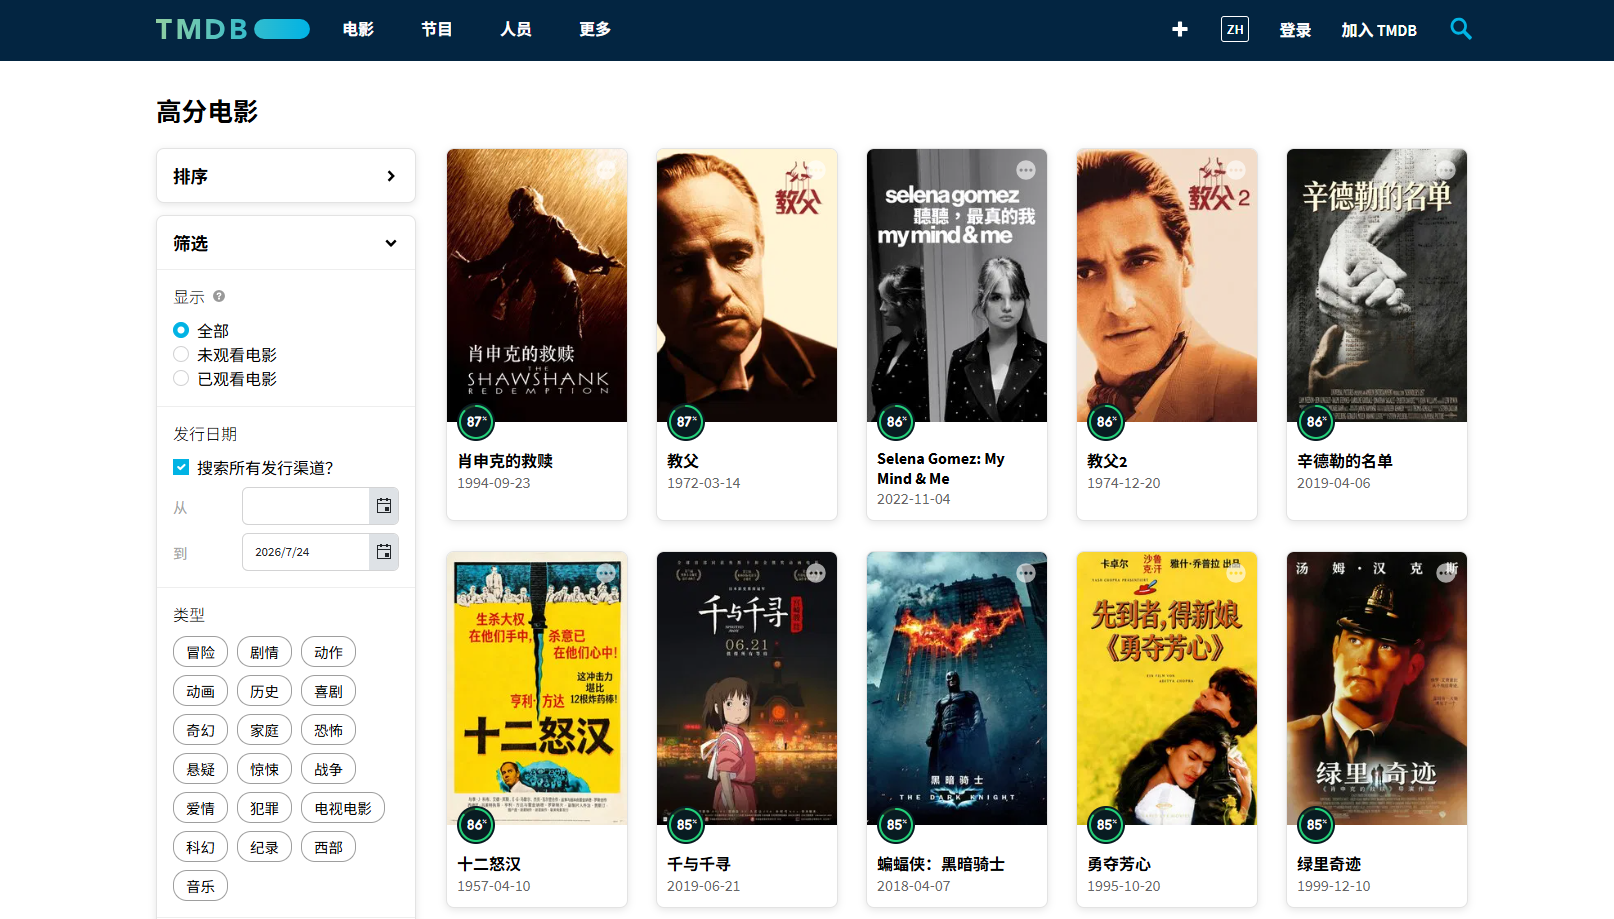

*讲义的高分电影列表：先从列表取得电影详情入口。*

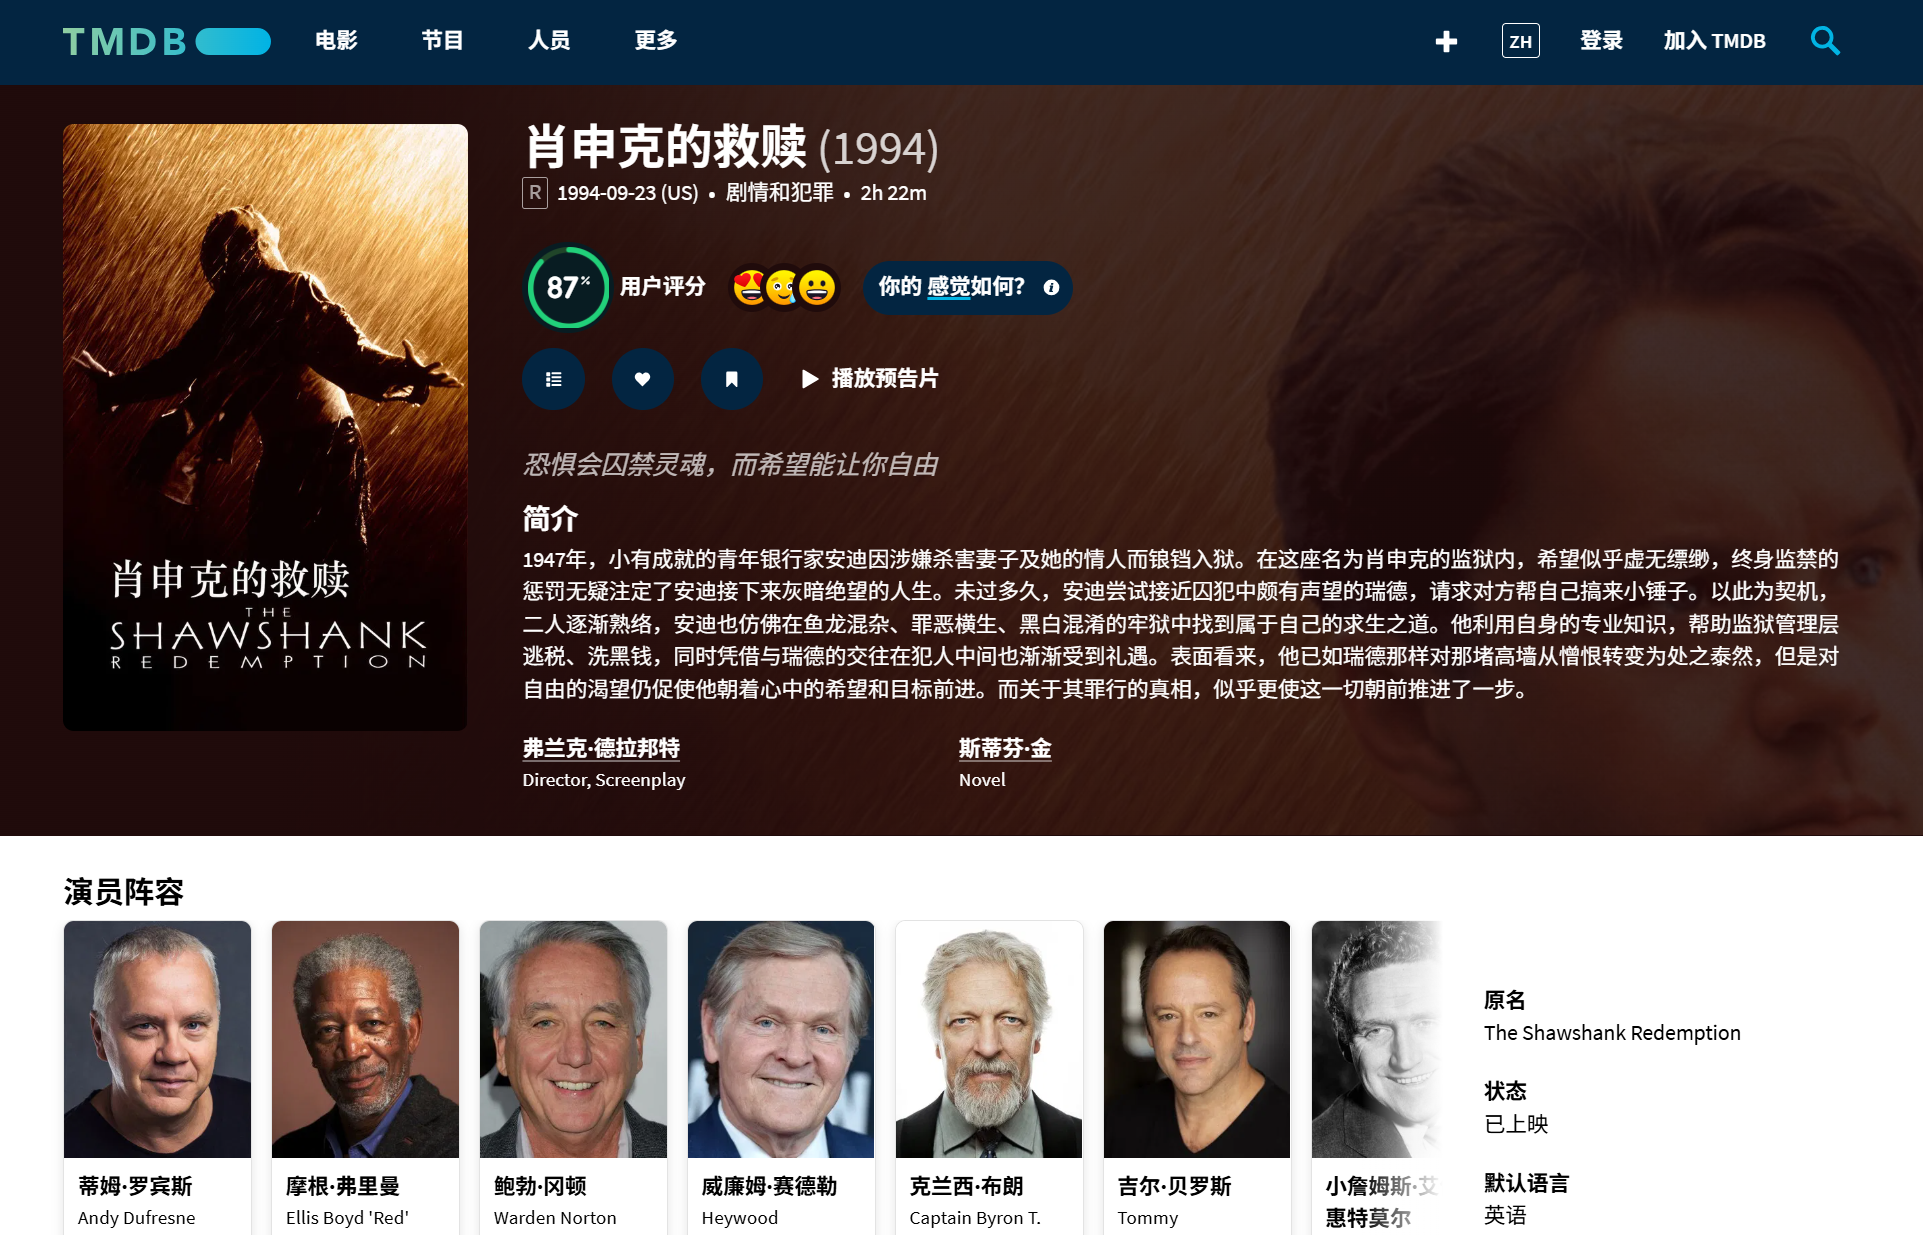

*讲义的电影详情页：名称、年份、日期、类型、时长、评分、简介及演职员等分布在不同区域。*

### 2. 要保存的 12 个字段

| 字段 | 含义 | 注意点 |
| --- | --- | --- |
| 电影名 | 详情页的电影标题 | 不要把年份混进名称 |
| 年份 | 电影年份 | 课件原文本可能带括号 |
| 上映时间 | 页面展示的上映日期 | 可能附带地区，如 (US) |
| 类型 | 剧情、犯罪等分类 | 一部电影可以有多个类型 |
| 时长 | 电影时长 | 原文本有小时和分钟，清洗后统一为分钟 |
| 评分 | 用户评分 | 课件展示百分制，87 表示 87%，不要悄悄当作 87/10 |
| 语言 | 原始语言或页面展示的默认语言 | 与网页本身使用中文或英文不同 |
| 导演 | Director 对应人员 | 可能有多位 |
| 作者 | 编剧、故事或原著相关人员 | 要按人物职责字段判断 |
| 主演 | 演员列表 | 提取展示姓名，不要误把角色名当成演员名 |
| Slogan | 宣传语、标语，页面常称 tagline | 有的电影可能没有 |
| 简介 | 剧情概述 | 可能包含多段文本和嵌套标签 |

**补充：**“作者”在讲义中没有进一步拆成单独列。参考实现将 Writer、Screenplay、Story、Novel 相关人员归入这一列，导演仍单独保存；同一个人可以同时是导演和编剧。

### 3. 讲义的实现步骤

1. 明确目标站点 robots 中的访问规则。
2. 观察列表页和详情页结构，拆解步骤。
3. 获取高分电影列表。
4. 遍历列表，取得每部电影的详情页。
5. 提取要求的电影字段。
6. 清洗年份、日期、时长等数据。
7. 把结果保存到 CSV。

把步骤画成数据流：

```text
榜单第 1 页、第 2 页……
      ↓
电影详情链接（按榜单顺序去重）
      ↓
逐个读取电影详情页
      ↓
12 个字段的原始值
      ↓
清洗、检查、组织字典
      ↓
写入统一列顺序的 CSV
```

### 4. Top100 不能只靠文件名保证

**补充：**如果只取得 20 条，就不能把文件命名为 Top100 并声称完成。需要检查分页、重复电影、失败详情页和最终数量。

“每页 20 条，所以循环 5 次”必须建立在目标页面确实支持这种分页方式的前提上。某些网页通过“加载更多”按钮和额外请求获取数据，不能凭空认为加一个 `?page=2` 就一定拿到第二页。

本章参考程序把列表页地址作为输入，让采集逻辑与具体分页机制分开。只有确认站点规则、实际分页响应和 XPath 都适用，才能把它用于线上目标。

## 九、CSV：把电影保存成表格

### 1. CSV 是什么

CSV 是 Comma-Separated Values，逗号分隔值。它是一种表示表格数据的文本格式，一般一条记录对应一行，不同字段用逗号隔开。

CSV 可以被 Excel、WPS、Python 等工具读取。它本身不是 Excel 的 `.xlsx` 文件，不保存工作簿格式、复杂样式和单元格公式结构等完整信息。

### 2. 课件方式一：直接写文本

课件用“姓名、年龄、性别、爱好”演示直接写入。原例把 `Python,Java` 用单引号包起来：

```text
王林,29,男,'Python,Java'
```

**勘误：**标准 CSV 通常使用双引号作为字段引用符。这里的单引号只是普通字符，字段中的逗号仍会被当作分隔符，四列数据可能被误读成五列。

修正后的直接写入例子：

```python
from pathlib import Path

Path("resources").mkdir(exist_ok=True)
with open("resources/01.csv", "w", encoding="utf-8", newline="") as f:
    f.write("姓名,年龄,性别,爱好\n")
    f.write('王林,29,男,"Python,Java"\n')
    f.write("红蝶,18,女,Java\n")
```

产生的内容：

```text
姓名,年龄,性别,爱好
王林,29,男,"Python,Java"
红蝶,18,女,Java
```

手动拼接适合认识格式，但字段里还可能出现双引号和换行，规则很快会变复杂。项目中优先让 csv 模块处理。

### 3. 课件方式二：csv.DictWriter

```python
import csv
with open("resources/02.csv", "w", encoding="utf-8", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["姓名", "年龄", "性别", "爱好"])
    writer.writeheader()
    writer.writerow({"姓名": "王林", "年龄": 29, "性别": "男", "爱好": "Python,Java"})
    writer.writerow({"姓名": "红蝶", "年龄": 18, "性别": "女", "爱好": "Java"})
```

| 写法 | 作用 |
| --- | --- |
| `fieldnames=[...]` | 指定列名及输出顺序 |
| `writer.writeheader()` | 写表头 |
| `writer.writerow({...})` | 把一个字典写成一条记录 |
| `writer.writerows(records)` | 一次写多条记录，参考项目会用到 |
| `newline=""` | 让 csv 模块管理换行，避免某些环境下出现多余空行 |

csv 是标准库，可以直接 `import csv`。DictWriter 会根据字段内容处理必要的引号，不需要自己在 `"Python,Java"` 外面再包一层引号字符串。

### 4. 补充：读回来检查列有没有错位

```python
import csv

with open("resources/02.csv", "r", encoding="utf-8", newline="") as f:
    rows = list(csv.DictReader(f))

print(rows[0])
print(rows[0]["爱好"])
```

输出：

```text
{'姓名': '王林', '年龄': '29', '性别': '男', '爱好': 'Python,Java'}
Python,Java
```

CSV 读取后通常得到字符串。写入时年龄是整数 29，读取后是 `"29"`，如果要计算还需转换；CSV 本身没有替你保留 Python 类型。

### 5. 编码和复杂字段

**补充：**某些 Windows Excel 版本直接打开 UTF-8 CSV 时，中文识别不理想。可以使用 `encoding="utf-8-sig"` 写入，增加 UTF-8 BOM，方便这些版本识别。后面的项目采用此方式，读取时也可以使用 utf-8-sig。

电影类型、演职员、简介经常包含逗号、引号或换行。csv 模块会按规则处理；不要用简单的 `line.split(",")` 读取 CSV，也不要把“文件中的物理行数”直接当作记录数。

## 十、案例拓展：数据提取后还要清洗

### 1. 课件中的原始数据

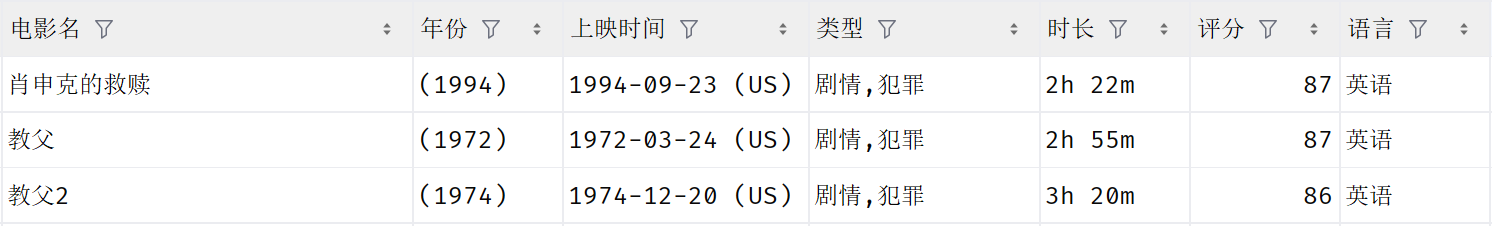

*讲义中的电影原始字段：年份带括号，日期带地区，时长使用小时和分钟。*

处理后的目标应为：

| 原始年份 | 原始上映时间 | 原始时长 | 清洗后年份 | 清洗后日期 | 分钟数 |
| --- | --- | --- | --- | --- | --- |
| (1994) | 1994-09-23 (US) | 2h 22m | 1994 | 1994-09-23 | **142** |
| (1972) | 1972-03-24 (US) | 2h 55m | 1972 | 1972-03-24 | **175** |
| (1974) | 1974-12-20 (US) | 3h 20m | 1974 | 1974-12-20 | **200** |

> **勘误：**PPT 转换结果把前两项时长写成 144 和 177。按截图的原始值，2 × 60 + 22 = 142，2 × 60 + 55 = 175。这里修正的是换算，不修改原始输入去凑错误答案。

### 2. 用字符串方法处理

格式固定时，可以用切片、分割或去除字符：

```python
year_text = "(1994)"
release_text = "1994-09-23 (US)"
runtime_text = "2h 22m"

year = int(year_text.strip("()"))
release_date = release_text.split()[0]
hours_text, minutes_text = runtime_text.split()
minutes = int(hours_text.removesuffix("h")) * 60 + int(minutes_text.removesuffix("m"))

print(year)
print(release_date)
print(minutes)
```

输出：

```text
1994
1994-09-23
142
```

这段代码假定时长始终由“小时 + 分钟”两部分组成。若出现 `"95m"` 或 `"2h"`，直接解包两个值就会失败。这是引入正则表达式处理多种形式的原因。

另外，`strip("()")` 的含义是从两端去掉这些字符，并非精确识别一对括号；`removesuffix("h")` 才是移除指定后缀。实际代码要根据数据格式选择工具。

## 十一、正则表达式：按文本规则查找与提取

### 1. 正则表达式是什么

正则表达式（Regular Expression）是描述文本模式的一套语法，可以用于查找、提取和替换符合规则的字符序列。讲义把它称为文本处理中的“高级查找和匹配公式”。

Python 使用标准库 `re` 处理正则，不需要 pip 安装。

课件示例：

```text
1[3-9]\d{9}
```

含义是：

1. 第一个字符必须是 `1`。
2. 第二个字符是 `3` 到 `9` 中的一个。
3. 后面紧跟 9 个数字。

这样总共匹配 11 位数字。它是用于讲解规则的手机号形式示例，并不能证明一个号码真实存在或已经分配。

### 2. re.match、re.search、re.findall

| 函数 | 从哪里找 | 成功时返回 | 没找到时返回 |
| --- | --- | --- | --- |
| `re.match(pattern, text)` | 仅从字符串开头尝试匹配 | Match 对象 | `None` |
| `re.search(pattern, text)` | 在字符串中查找第一个匹配 | Match 对象 | `None` |
| `re.findall(pattern, text)` | 找出所有非重叠匹配 | 列表 | `[]` |

**勘误：**findall 返回的不是 Match 对象列表。没有捕获组时通常返回字符串列表；有捕获组时，返回内容会随分组变化，多个捕获组可能返回元组列表。

### 3. 课件电话示例，修正空匹配处理

```python
import re

s = "我的手机号是18809091231你记住了吗? 我的另一个手机号是18800001266，QQ号是1779989922你记住了吗?"
pattern = r"1[3-9]\d{9}"

result = re.match(pattern, s)
print(result.group() if result else None)

result = re.search(pattern, s)
print(result.group() if result else None)

result = re.findall(pattern, s)
print(result)
```

输出：

```text
None
18809091231
['18809091231', '18800001266']
```

为什么第一个是 None？字符串以“我的手机号是”开头，开头并不是目标号码，所以 match 失败。

> **勘误：**课件直接对第一条 match 结果执行 `result.group()`，会因为 result 是 None 而报错，后两段也就执行不到。上面先判断是否匹配成功。QQ 号只有 10 位，不满足该表达式的 11 位规则。

### 4. Match 对象与 group()

Match 对象包含匹配到的文本、位置等信息。`group()` 或 `group(0)` 取完整匹配，`group(1)` 等取括号定义的捕获组。

```python
import re

result = re.search(r"([0-9]{4})-([0-9]{2})-([0-9]{2})", "上映：1994-09-23 (US)")
if result:
    print(result.group(0))
    print(result.group(1))
    print(result.groups())
```

输出：

```text
1994-09-23
1994
('1994', '09', '23')
```

### 5. 字符串前的 r 是什么意思

`r"..."` 是 Python 的原始字符串写法，让反斜杠不先按照普通 Python 字符串转义规则处理。正则经常包含反斜杠，所以常用这种写法。

```python
print(len("\n"))
print(len(r"\n"))
```

输出 1 和 2：前者是一个换行字符，后者是反斜杠与字母 n 两个字符。

**勘误与补充：**r 影响的是 Python 字符串的解析，不是关闭正则语法。`re.search(r"\d+", "2026")` 中的 `\d` 仍然会被正则引擎解释为数字类别；`r"\n"` 作为正则模式时仍然能匹配换行。

## 十二、讲义正则语法表与完整示例

### 1. 普通字符与字符类别

| 表达式 | 含义 | 说明 |
| --- | --- | --- |
| 普通字符 | 通常匹配自身 | 如字母、数字、汉字；特殊符号需留意转义 |
| `.` | 默认匹配除换行以外的一个字符 | 使用 DOTALL 标志时规则会不同 |
| `\d` | 数字字符 | Python Unicode 模式下不只限 ASCII 0～9 |
| `\D` | 非数字字符 | 与 \d 相反 |
| `\w` | 单词字符 | Unicode 字母数字与下划线，包含许多中文字符 |
| `\W` | 非单词字符 | 与 \w 相反 |
| `\s` | 空白字符 | 包括空格、制表符、换行等 |
| `\S` | 非空白字符 | 与 \s 相反 |
| `[3-9]` | 在给定范围中选择一个字符 | 课件手机号模式使用了它 |
| `[0-9]` | 一个 ASCII 数字 | 需要严格限制 0～9 时更直观 |

> **勘误：**课件把 \w 只概括为 a-z、A-Z、0-9、下划线，是常见简化。Python 对 str 使用 Unicode 匹配，范围更广；\d 也不仅仅是 ASCII 数字，\s 也不只有空格和制表符。

### 2. 数量、分组与位置

| 表达式 | 含义 |
| --- | --- |
| `*` | 前面的单元重复 0 次或更多次 |
| `+` | 重复 1 次或更多次 |
| `?` | 重复 0 次或 1 次 |
| `{m}` | 恰好重复 m 次 |
| `{m,}` | 至少重复 m 次 |
| `{m,n}` | 重复 m 到 n 次，包括边界 |
| <code>&#124;</code> | 在左右表达式中选择其一 |
| `()` | 将内容组成一个组，默认也形成捕获组 |
| `^` | 默认匹配字符串开头 |
| `$` | 默认匹配字符串结尾，也可匹配末尾换行之前 |

**勘误：**量词问号必须是英文半角 `?`。课件个别位置的全角 `？` 会被当成普通全角字符，不能起到“0 或 1 次”的作用。

### 3. 课件表达式逐一解释

| 表达式 | 含义 |
| --- | --- |
| `1[3-9]\d*` | 1、一个 3～9 的数字，后接任意数量数字，最短只有 2 位 |
| `1[3-9]\d+` | 后面至少再接 1 个数字，最短 3 位 |
| `1[3-9]\d?` | 后面最多再接 1 个数字，总长度为 2 或 3 位 |
| `1[3-9]\d{9}` | 后面恰好 9 个数字，总长度 11 位 |
| `1[3-9]\d{9,}` | 总长度至少 11 位 |
| `^1[3-9]\d{9}$` | 从开头到结尾符合课件号码形式 |
| <code>^1(3&#124;5&#124;7&#124;8&#124;9)\d{9}$</code> | 第二位只允许 3、5、7、8、9；不包含 4、6 |
| `ab+` | 一个 a，后接至少一个 b，例如 ab、abbb |
| `(ab)+` | 整个 ab 组重复，例如 ab、abab |

量词只约束紧挨着它的前一个单元。括号会把多个字符组合成一个单元，因此 `ab+` 与 `(ab)+` 不同。

### 4. 补充：提取与整体校验不一样

search 的目的通常是“文本中有没有这一段”；整体校验要判断“整段输入是否符合规则”。

```python
import re

print(re.search(r"1[3-9][0-9]{9}", "联系我：18809091231") is not None)
print(re.fullmatch(r"1[3-9][0-9]{9}", "联系我：18809091231") is not None)
print(re.fullmatch(r"1[3-9][0-9]{9}", "18809091231") is not None)
```

输出：

```text
True
False
True
```

`fullmatch` 是为避免混淆而补充的方法：它要求整个字符串匹配，也避免仅用 `$` 时忽略末尾换行细节。若需要从长串数字中提取独立号码，还应考虑两侧数字边界；本章原例用于认识基本模式。

### 5. findall 遇到分组

```python
import re

text = "1994-09-23 1972-03-24"
print(re.findall(r"[0-9]{4}-[0-9]{2}-[0-9]{2}", text))
print(re.findall(r"([0-9]{4})-[0-9]{2}-[0-9]{2}", text))
print(re.findall(r"([0-9]{4})-([0-9]{2})-([0-9]{2})", text))
```

输出：

```text
['1994-09-23', '1972-03-24']
['1994', '1972']
[('1994', '09', '23'), ('1972', '03', '24')]
```

这也解释了为什么不能把 findall 的返回值一概称为 Match 列表。

### 6. 本节复习

- 点号默认是否匹配换行？不匹配。
- \d 与 \D、\w 与 \W、\s 与 \S 的关系？分别是对应字符类别及其相反类别。
- *、+、? 的最少次数？分别是 0、1、0，? 最多 1 次。
- {m}、{m,}、{m,n} 的区别？精确次数、至少次数、次数区间。
- 竖线与括号的作用？选择其一，以及组成并捕获一个组。
- ^ 与 $ 控制什么？匹配的位置；整体校验也可以明确使用 fullmatch。

## 十三、电影字段清洗的参考实现

> **补充：参考实现。**讲义提出了“怎样处理年份、日期、时长”的问题，没有给出完整函数。下面把它们补成可复用逻辑，完整函数会与电影解析代码一起放在 `movie_parser.py` 中。

### 1. 年份：从带括号文本中取出四位数字

```python
import re

match = re.search(r"\b([0-9]{4})\b", "(1994)")
year = int(match.group(1)) if match else ""
print(year)
```

输出 `1994`。`\b` 是单词边界，`([0-9]{4})` 是要提取的年份组。没有匹配时返回空字符串，表示字段缺失，不强行编造年份。

### 2. 上映时间：提取日期并验证

```python
import re
from datetime import datetime

text = "1994-09-23 (US)"
match = re.search(r"[0-9]{4}-[0-9]{2}-[0-9]{2}", text)
release_date = (
    datetime.strptime(match.group(), "%Y-%m-%d").date().isoformat()
    if match else ""
)
print(release_date)
```

输出 `1994-09-23`。

正则先识别“年-月-日”的形式，`datetime.strptime` 再验证真实日历日期。像 `2026-02-30` 这样的文本虽然形式匹配，却不是有效日期，不能仅凭正则形状就当作正确日期。

**补充：**课件使用年-月-日。若页面改成日/月/年，或因为语言设置显示不同格式，应明确输入格式并调整转换，不要随意交换数字位置。不同地区上映日期也可能不同，笔记保留页面展示的含义。

### 3. 时长：统一转换成分钟

时长的参考规则支持：

| 输入 | 输出 |
| --- | --- |
| `2h 22m` | 142 |
| `2h 55m` | 175 |
| `3h 20m` | 200 |
| `95m` | 95 |
| `2h` | 120 |
| 空白 | 空字符串，表示缺失 |

使用的表达式是：

```text
(?:(\d+)\s*h)?\s*(?:(\d+)\s*m)?
```

拆开看：

- `(\d+)` 捕获数字。
- `\s*` 允许出现空白。
- `h`、`m` 分别表示小时和分钟。
- `(?:...)` 是非捕获分组，用来把一整段归组，但不额外占据 group 编号。
- 外面的 `?` 表示该部分可以省略。
- 小时数和分钟数因此分别落在第 1、2 个捕获组中。

**补充：**两个部分都可省略，所以还要额外拒绝“匹配成功却什么也没提取到”的情况。对于非空但无法识别的文本，如 `"未知"`，参考代码抛出错误提醒检查，不把它偷偷换算为 0 分钟。

### 4. 评分、类型、人员与缺失值

参考实现采用以下约定：

| 字段 | 保存方式 |
| --- | --- |
| 年份 | 能提取时保存整数 |
| 上映时间 | 统一为 YYYY-MM-DD 字符串 |
| 时长 | 统一为整数分钟 |
| 评分 | 沿用课件百分制，范围 0～100 |
| 多个类型、导演、作者、主演 | 各自合成一个字段，用逗号连接，由 CSV Writer 处理外层引用 |
| 缺失的可选字段 | 保存空字符串 |
| 必需的电影标题缺失 | 报错，提示核对是否拿错页面或选择器失效 |

空字符串和 0 含义不同：空字符串表示没有取得值，0 则是具体数值。不要为了让程序“不报错”，把所有缺失值都改成 0。

## 十四、完整案例代码：列表、详情、清洗与 CSV

### 1. 为什么给出离线教学页面

本章电影站点的完整网页源文件未包含在 PPT 中，而且当前站点对本自动客户端限制抓取。因此下面采用：

- 课程截图展示真实页面布局与需要的字段。
- 明确标注的教学 HTML 展示对应结构，供 XPath 练习。
- 同一套解析、去重、数量检查和写文件函数完成整个流程。
- 线上请求作为可替换的数据来源，必须先满足当前访问规则并核对实际结构。

**离线样例只有 3 部，不是实时 Top100。**电影名、年份、日期、时长、评分用来对应课件示例；演职员与简介中的“示例”文字是练习内容，不作为真实电影资料。

### 2. 文件结构

```text
movie-study/
    .venv/
    movie_parser.py
    demo_movie.py
    http_client.py       ← 需要学习线上请求时使用
    demo_pages/          ← 离线运行时自动生成
    output/              ← 保存练习 CSV
```

最小离线运行只需要前两个 Python 文件以及 lxml。创建环境与安装命令已经在本章开头给出；如果环境已准备好，不必重复创建。

### 3. movie_parser.py：完整解析与保存代码

```python
import csv
import re
from datetime import datetime
from pathlib import Path
from urllib.parse import urljoin, urlsplit
from lxml import html

FIELDS = [
    "电影名", "年份", "上映时间", "类型", "时长", "评分",
    "语言", "导演", "作者", "主演", "Slogan", "简介",
]


def clean_text(value):
    return " ".join(value.split())


def class_is(name):
    # class 可以有多个值；按完整类名匹配，避免 card 匹配到 postcard。
    return f"contains(concat(' ', normalize-space(@class), ' '), ' {name} ')"


def first_text(node, expression):
    values = node.xpath(expression)
    return clean_text(str(values[0])) if values else ""


def element_text(node, expression):
    values = node.xpath(expression)
    return clean_text(values[0].text_content()) if values else ""


def extract_year(text):
    match = re.search(r"\b([0-9]{4})\b", text)
    return int(match.group(1)) if match else ""


def extract_date(text):
    match = re.search(r"[0-9]{4}-[0-9]{2}-[0-9]{2}", text)
    if not match:
        return ""
    # 再验证真实日历日期，避免把 2026-02-30 当作有效日期。
    return datetime.strptime(match.group(), "%Y-%m-%d").date().isoformat()


def runtime_minutes(text):
    text = clean_text(text)
    if not text:
        return ""
    match = re.fullmatch(r"(?:(\d+)\s*h)?\s*(?:(\d+)\s*m)?", text, re.I)
    if not match or not any(match.groups()):
        raise ValueError(f"无法识别时长：{text}")
    hours, minutes = match.groups()
    if hours is not None and int(minutes or 0) >= 60:
        raise ValueError(f"小时后的分钟数应小于 60：{text}")
    return int(hours or 0) * 60 + int(minutes or 0)


def parse_score(text):
    text = text.strip().rstrip("%")
    if not text:
        return ""
    value = float(text)
    if not 0 <= value <= 100:
        raise ValueError(f"百分制评分越界：{text}")
    return int(value) if value.is_integer() else value


def movie_links(content, page_url):
    doc = html.fromstring(content)
    links, seen = [], set()
    expression = f"//div[{class_is('card')}]//h2/a/@href"
    for href in doc.xpath(expression):
        absolute = urljoin(page_url, href)
        parts = urlsplit(absolute)
        match = re.match(r"^/movie/([0-9]+)(?:-[^/]*)?/?$", parts.path)
        if parts.netloc != urlsplit(page_url).netloc or not match:
            continue
        movie_id = match.group(1)
        if movie_id not in seen:
            seen.add(movie_id)
            links.append((movie_id, absolute))
    return links


def parse_detail(content):
    doc = html.fromstring(content)
    name = element_text(doc, f"//div[{class_is('title')}]/h2/a")
    if not name:
        raise ValueError("没有找到电影标题，请检查 HTML 是否为详情页及 XPath 是否适用")
    genres = doc.xpath(f"//span[{class_is('genres')}]/a/text()")
    directors, writers = [], []
    for person in doc.xpath(f"//ol[{class_is('people')}]/li[{class_is('profile')}]"):
        person_name = element_text(person, "./p/a")
        jobs = element_text(person, f"./p[{class_is('character')}]")
        jobs = {job.strip() for job in jobs.split(",")}
        if person_name and "Director" in jobs:
            directors.append(person_name)
        if person_name and jobs & {"Writer", "Screenplay", "Story", "Novel"}:
            writers.append(person_name)
    actors = doc.xpath(f"//ol[{class_is('scroller')}]/li/p/a/text()")
    language = ""
    for paragraph in doc.xpath(f"//section[{class_is('facts')}]/p"):
        label = element_text(paragraph, "./strong")
        if label in ("默认语言", "原始语言", "Original Language"):
            language = clean_text("".join(paragraph.xpath("./text()")))
            break
    return {
        "电影名": name,
        "年份": extract_year(element_text(doc, f"//span[{class_is('release_date')}]")),
        "上映时间": extract_date(element_text(doc, f"//span[{class_is('release')}]")),
        "类型": ",".join(clean_text(value) for value in genres if value.strip()),
        "时长": runtime_minutes(element_text(doc, f"//span[{class_is('runtime')}]")),
        "评分": parse_score(first_text(doc, f"//*[{class_is('user_score_chart')}]/@data-percent")),
        "语言": language,
        "导演": ",".join(dict.fromkeys(directors)),
        "作者": ",".join(dict.fromkeys(writers)),
        "主演": ",".join(dict.fromkeys(clean_text(a) for a in actors if a.strip())),
        "Slogan": element_text(doc, f"//h3[{class_is('tagline')}]"),
        "简介": element_text(doc, f"//div[{class_is('overview')}]"),
    }


def collect_movies(fetch_html, list_urls, limit=100):
    if limit <= 0:
        raise ValueError("limit 必须大于 0")
    records, seen = [], set()
    for page_url in list_urls:
        links = movie_links(fetch_html(page_url), page_url)
        if not links:
            raise ValueError(f"未找到电影链接，请检查页面结构：{page_url}")
        for movie_id, detail_url in links:
            if movie_id in seen:
                continue
            record = parse_detail(fetch_html(detail_url))
            seen.add(movie_id)
            records.append(record)
            if len(records) == limit:
                return records
    raise ValueError(f"目标为 {limit} 部，实际只收集到 {len(records)} 部，请检查分页")


def save_movies(records, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    # utf-8-sig 便于部分 Windows Excel 版本识别中文。
    with path.open("w", encoding="utf-8-sig", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=FIELDS)
        writer.writeheader()
        writer.writerows(records)
```

### 4. 逐步读懂解析代码

**class_is：匹配完整类名。**

HTML 的 class 可以包含多个值，例如 `class="card style_1"`。直接写 `@class='card'` 会漏掉它；简单的 `contains(@class, 'card')` 又可能误匹配 postcard。

参考函数在 class 两侧补空格，再检查完整类名：

```text
contains(concat(' ', normalize-space(@class), ' '), ' card ')
```

`normalize-space` 整理空白，`concat` 拼接字符串，`contains` 检查包含关系。这是为本案例补充的 XPath 用法。

**first_text 与 element_text：区分属性结果和元素结果。**

前者处理 `@data-percent` 这种已经是字符串的结果；后者先得到元素，再用 `text_content()` 取包含后代节点的文字。它们都在空结果时返回空字符串。

**movie_links：从列表找到详情页。**

函数先定位电影卡片下的 h2/a，再取 href。`urljoin` 把相对路径转换为绝对地址：

```python
from urllib.parse import urljoin

print(urljoin("https://example.invalid/movie/top-rated?page=1", "/movie/1-demo"))
```

输出：

```text
https://example.invalid/movie/1-demo
```

这个 example.invalid 是离线练习的占位地址，不会发出真实网络请求。真实站点的相对链接也需要结合列表页 URL 解析，不能简单用字符串硬拼所有路径。

代码只接纳相同站点的电影详情路径，并提取电影编号作为去重键。同一电影可能同时出现在相邻页面，甚至链接中的名称部分发生变化，用电影编号去重比只比较电影名更可靠。

**parse_detail：按字段语义找节点。**

| 内容 | 教学 HTML 中的定位依据 |
| --- | --- |
| 电影名 | title 区域 h2 中的 a |
| 年份 | release_date |
| 上映时间 | release |
| 类型 | genres 里面的 a |
| 时长 | runtime |
| 评分 | user_score_chart 的 data-percent 属性 |
| 导演与作者 | people 列表中的 profile，按 character 职责判断 |
| 主演 | scroller 演员列表中的姓名链接 |
| 语言 | facts 中带“默认语言”等标签的段落 |
| Slogan | tagline |
| 简介 | overview |

这些选择器对应本笔记的教学 HTML，并参考课件展示的布局。**没有把它们声称为已经对当前 TMDB 线上 DOM 验证过的选择器。**线上标签、语言和 class 发生变化时，需要重新检查。

**导演与作者为什么不能靠列表下标。**

课件中一个人可同时标注 `Director, Screenplay`，另一个人标注 `Novel`。因此代码先拆分职责，再判断归属；不能不看角色就把“第一人”永远当导演、“第二人”永远当作者。

**collect_movies：流程控制与 Top100 数量要求。**

函数依次读取列表页，再读取详情页；记录已处理编号，跨页去重，并保持列表顺序。达到 limit 即返回；列表地址用完仍不足目标数量就报错，不输出“已完成 Top100”的假结果。

`fetch_html` 是一个函数参数：把“从哪里获得 HTML”交给外部决定。离线时它读本地文件，线上时它可以调用检查规则的 HTTP 客户端。解析流程不需要为两种来源各写一遍。

**save_movies：统一字段顺序。**

保存时使用固定的 FIELDS、`newline=""` 和 `utf-8-sig`，自动处理字段中的逗号与引号。输出路径的父目录不存在时会先创建。

### 5. demo_movie.py：创建练习页面并运行

将下面代码保存到 `demo_movie.py`，与 `movie_parser.py` 放在同一目录：

```python
"""离线练习：生成 3 部电影的教学 HTML，验证完整采集流程。"""
from pathlib import Path
from urllib.parse import urlsplit, parse_qs
from html import escape
from movie_parser import collect_movies, save_movies

ROOT = Path(__file__).resolve().parent
PAGES = ROOT / "demo_pages"

# 年份、日期、时长、评分沿用课件截图；其他文字为教学样例。
# 这是 3 条练习数据，不是实时排名，也不是已抓到的 Top100。
SAMPLES = [
    ("1", "肖申克的救赎", "1994", "1994-09-23 (US)", "2h 22m", "87"),
    ("2", "教父", "1972", "1972-03-24 (US)", "2h 55m", "87"),
    ("3", "教父2", "1974", "1974-12-20 (US)", "3h 20m", "86"),
]


def make_demo_pages():
    PAGES.mkdir(exist_ok=True)
    for movie_id, name, year, release, runtime, score in SAMPLES:
        content = f"""<!doctype html>
<html lang="zh-CN"><head><meta charset="utf-8"></head><body>
<div class="title"><h2><a>{escape(name)}</a>
<span class="release_date">({year})</span></h2></div>
<span class="release">{release}</span>
<span class="genres"><a>剧情</a><a>犯罪</a></span>
<span class="runtime">{runtime}</span>
<div class="user_score_chart" data-percent="{score}"></div>
<h3 class="tagline">教学 Slogan：人生、选择与希望</h3>
<div class="overview"><p>用于练习的简介，含有逗号、"引号"与
<strong>嵌套标签</strong>。</p></div>
<ol class="people">
  <li class="profile"><p><a>示例导演</a></p>
      <p class="character">Director, Screenplay</p></li>
  <li class="profile"><p><a>示例原著作者</a></p>
      <p class="character">Novel</p></li>
</ol>
<ol class="people scroller"><li><p><a>示例演员甲</a></p></li>
<li><p><a>示例演员乙</a></p></li></ol>
<section class="facts"><p><strong>默认语言</strong> 英语</p></section>
</body></html>"""
        (PAGES / f"movie-{movie_id}.html").write_text(content, encoding="utf-8")
    # 第 2 页重复一部电影，专门验证跨页去重。
    for page, ids in [(1, ["1", "2"]), (2, ["2", "3"])]:
        cards = "".join(
            f'<div class="card style_1"><h2><a href="/movie/{i}-demo">'
            f'电影 {i}</a></h2></div>' for i in ids
        )
        (PAGES / f"list-{page}.html").write_text(
            f"<html><body>{cards}</body></html>", encoding="utf-8"
        )


def local_fetch(url):
    parts = urlsplit(url)
    if parts.path == "/movie/top-rated":
        page = parse_qs(parts.query)["page"][0]
        path = PAGES / f"list-{int(page)}.html"
    else:
        movie_id = parts.path.split("/")[-1].split("-")[0]
        path = PAGES / f"movie-{int(movie_id)}.html"
    return path.read_text(encoding="utf-8")


def main():
    make_demo_pages()
    urls = [
        "https://example.invalid/movie/top-rated?page=1",
        "https://example.invalid/movie/top-rated?page=2",
    ]
    records = collect_movies(local_fetch, urls, limit=3)
    output = ROOT / "output" / "电影练习_3条.csv"
    save_movies(records, output)
    print(f"离线练习完成：{len(records)} 条，保存到 {output}")
    for record in records:
        print(record["电影名"], record["年份"], record["上映时间"], record["时长"])


if __name__ == "__main__":
    main()
```

运行：

```powershell
.\.venv\Scripts\python.exe demo_movie.py
```

程序会创建两张列表练习页和三张详情练习页，然后读取这些页面，输出：

```text
离线练习完成：3 条，保存到 .../output/电影练习_3条.csv
肖申克的救赎 1994 1994-09-23 142
教父 1972 1972-03-24 175
教父2 1974 1974-12-20 200
```

第二张列表故意再放一次编号 2 的电影，让你可以看到去重并不是一句口号：两页共有四个链接，但最终只有三部不同的电影。

代码中 `html.escape` 把名称里的特殊字符转义为适合放入 HTML 的形式。这与解析库的 `lxml.html` 是两件事：前者来自标准库，后者是解析文档的第三方库。

生成 HTML 的 f-string 用来准备练习素材，实际采集时不需要你自己生成目标网页；它在这里的作用是让你无需外部资源就能练习完整流程。

### 6. 如何检查 CSV 结果

```python
import csv
from pathlib import Path

path = Path(__file__).resolve().parent / "output" / "电影练习_3条.csv"
with path.open(encoding="utf-8-sig", newline="") as f:
    reader = csv.DictReader(f)
    rows = list(reader)
    print(reader.fieldnames)

print("记录数：", len(rows))
print("第一部时长：", rows[0]["时长"])
print("第一部作者：", rows[0]["作者"])
```

预期有 12 个字段、3 条记录，第一部时长为字符串 `"142"`，作者列包含“示例导演,示例原著作者”。后者说明一个人可以同时承担导演和编剧职责。

简介中故意带了逗号、英文双引号和嵌套标签，可以检查：

- CSV 读取后列有没有错位。
- 嵌套标签里的文字有没有漏掉。
- 多余换行和空白有没有整理。
- 每一列是否仍然对应正确字段。

### 7. 数量不够时会发生什么

如果把演示的 `limit=3` 改成 `limit=100`，两个列表页只提供三部不同电影，函数应明确报错：

```text
目标为 100 部，实际只收集到 3 部，请检查分页
```

这是正确的数量检查结果，不应复制这三部电影凑够 100 行，也不应仅把文件名改成 Top100。

## 十五、线上请求怎样接入同一个流程

### 1. 补充：请求客户端

下面把课件中的 robots 检查、请求间隔、Requests 调用补成一个基础教学客户端。保存为 `http_client.py`：

```python
"""教学 HTTP 客户端：检查 robots，顺序请求，保留访问间隔。"""
import time
from urllib.parse import urlsplit
from urllib.robotparser import RobotFileParser
import requests

USER_AGENT = "OpenAI-EducationExample/1.0"


class PoliteClient:
    def __init__(self, base_url, interval=5):
        parts = urlsplit(base_url)
        self.origin = f"{parts.scheme}://{parts.netloc}"
        self.interval = max(5.0, float(interval))
        self.last_request = 0.0
        self.session = requests.Session()
        self.session.headers["User-Agent"] = USER_AGENT
        self.rules = RobotFileParser()
        try:
            response = self._request(self.origin + "/robots.txt")
            response.encoding = "utf-8"
            self.rules.parse(response.text.splitlines())
            delay = self.rules.crawl_delay(USER_AGENT)
            if delay is not None:
                self.interval = max(self.interval, delay)
        except Exception:
            self.session.close()
            raise

    def _request(self, url):
        elapsed = time.monotonic() - self.last_request
        if elapsed < self.interval:
            time.sleep(self.interval - elapsed)
        try:
            response = self.session.get(url, timeout=20, allow_redirects=False)
        finally:
            self.last_request = time.monotonic()
        if response.is_redirect:
            raise RuntimeError("遇到重定向，请核对目标地址和对应规则后使用正确 URL")
        response.raise_for_status()
        return response

    def get(self, url):
        parts = urlsplit(url)
        if f"{parts.scheme}://{parts.netloc}" != self.origin:
            raise ValueError("本客户端只访问初始化时指定的站点")
        if not self.rules.can_fetch(USER_AGENT, url):
            raise PermissionError(f"robots.txt 不允许当前客户端访问：{url}")
        return self._request(url).content

    def close(self):
        self.session.close()
```

这个客户端做了几件事：

1. 使用明确的 User-Agent 标识。
2. 先获取当前站点 robots.txt，再解析规则。
3. 检查每一个目标 URL 是否允许当前标识访问。
4. 在请求之间留出间隔，并考虑可解析的 Crawl-delay。
5. 使用超时，遇到失败状态停止。
6. 不自动跟随未经核对的重定向，也不把同一个规则用于其他站点。

`RobotFileParser` 是 Python 标准库提供的基础 robots 解析器。对于复杂规则或站点扩展，应结合协议和实际规则核对；它不能代替网站条款或授权判断。

本例对 robots 无法获取、请求失败和重定向采用停止处理，是教学代码的保守选择，不表示 robots 协议对所有状态码都只有这一种处理方式。

### 2. 用它获取 TIOBE 页面

```python
from pathlib import Path
from http_client import PoliteClient

client = PoliteClient("https://www.tiobe.com")
try:
    content = client.get("https://www.tiobe.com/tiobe-index/")
    path = Path(__file__).resolve().parent / "resources" / "tiobe.html"
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
finally:
    client.close()
```

这可以替代前面的最小请求脚本。保存后，仍使用前面的 `parse_tiobe.py` 进行解析。获取方式变了，解析目标仍然是 HTML。

### 3. 电影线上模式的连接方式

**条件：**只有在当前规则允许所用客户端访问，而且已经核对真实列表分页和详情选择器时，才适合用下面的连接方式。PPT 的截图不能证明这些条件在现在仍然成立。

下面展示程序如何连接，列表地址文件必须由实际核对结果准备，每行一个允许访问的列表页 URL：

```python
from pathlib import Path
from http_client import PoliteClient
from movie_parser import collect_movies, save_movies

root = Path(__file__).resolve().parent
list_urls = [
    line.strip()
    for line in (root / "list_urls.txt").read_text(encoding="utf-8").splitlines()
    if line.strip()
]
if not list_urls:
    raise ValueError("请先准备并核对列表页地址")

client = PoliteClient("https://www.themoviedb.org")
try:
    records = collect_movies(client.get, list_urls, limit=100)
    save_movies(records, root / "output" / "电影Top100.csv")
finally:
    client.close()
```

按整理时的 TMDB robots，本示例使用的 OpenAI 客户端标识会被拒绝，程序应停止。因此这段是完整流程的连接示例，**不是声称当前已经可以抓到 100 部电影**。学习解析时直接运行离线样例即可，不需要为完成这一章绕过访问限制。

### 4. 为什么单纯更换 XPath 可能仍然没有数据

若浏览器能看到内容，而原始 HTML 没有，可能是：

- 页面在 JavaScript 执行后另行加载数据。
- 需要点击“加载更多”才出现下一批。
- 返回的是登录页、限制访问页或其他非目标页面。
- 不同语言或地区设置改变了页面内容。

首先确认“返回内容是什么”，再决定解析方式。遇到访问限制时停止；在允许获取的场景，按实际页面或官方提供的数据接口方案调整。本章不额外展开浏览器自动化或其他框架。

## 十六、贯穿本章的检查方法与复习

### 1. 常见问题定位

| 现象 | 优先检查 |
| --- | --- |
| Requests 无法导入 | 安装依赖与运行代码是否使用同一个解释器 |
| 请求超时 | 连接、网络状况、服务响应；不要无间隔反复请求 |
| 返回 403、429 等 | 查看访问规则或频率限制，停止并核对原因 |
| 状态码成功但数据为空 | 是否拿到目标 HTML，是否是脚本后加载内容 |
| XPath 总是空列表 | 路径、标签、属性和实际文档树是否一致 |
| 每行结果都相同 | 是否误用全局 //，应改为当前节点的 ./ 或 .// |
| 表格列错位 | 是否只提取 td/text()，漏掉空值或嵌套文字 |
| IndexError | 是否在空查询结果上直接使用 [0] |
| NoneType 没有 group | 正则没有匹配到，却直接调用了 group |
| CSV 多出空行 | 是否使用 newline="" |
| 中文显示异常 | 实际编码与读取方式是否一致，Excel 是否需要 UTF-8 BOM |
| CSV 列数比预期多 | 是否手动拼接逗号，字段引用是否正确 |
| 结果不足 100 条 | 分页、去重、访问失败或详情解析是否完整 |
| 时长换算错误 | 小时先乘 60，再加分钟，不要直接拼接数字 |

### 2. 讲义核心问题与答案

**网络机器人是什么？**按预设规则自动访问并获取网络数据的程序。

**基本工作流程是什么？**请求页面、解析提取、清洗处理、存储；开始前确认访问规则。

**Requests、lxml、XPath 的分工？**Requests 取响应，lxml 解析文档，XPath 指定要找什么节点。

**HTML、CSS、JavaScript 的分工？**结构内容、外观样式、交互行为。

**为什么 XPath 取链接要用 @href？**链接的目标保存在属性中，显示文字是另外的文本内容。

**为什么循环里常用 .//？**让查询相对于当前节点，而不是重复查询整个页面。

**为什么要逐个 td 提取？**保留单元格位置，避免空值或嵌套标签造成列错位。

**CSV 中含逗号的字段怎么办？**用符合 CSV 规则的引用；实际项目让 csv 模块自动处理。

**match、search、findall 的区别？**开头尝试、找到首个匹配、找到全部非重叠匹配；前两者可能返回 None，findall 返回列表。

**r 字符串会关闭正则转义吗？**不会，它只影响 Python 字符串层面的解析。

**为什么需要正则之后再验证日期？**形式匹配不代表日期真实存在。

**怎样才算完成 Top100？**在确定的榜单顺序和访问条件下取得前 100 部不同电影、成功提取字段，并验证输出数量；不能拿三条样例冒充。

### 3. 本章成果与资料

学完应能独立解释并实现：

```text
明确目标与访问规则
    ↓
Requests 取得 HTML
    ↓
lxml 建立文档树，XPath 选择目标
    ↓
列表页提取详情链接，去重并保持顺序
    ↓
详情页提取 12 个字段
    ↓
字符串方法和正则清洗
    ↓
csv.DictWriter 写入可读取的表格
```

主要来源为桌面《第4章 - Python项目实战之网络机器人.pptx》，共 40 页。教学页全部纳入对应主题；重复演示合并；第 40 页为品牌结束页。第 3、27 页备注中的“爬虫工作流程”和“robots 合法合规性”已分别整理在前两节。

相关入口：

- [TIOBE Index](https://www.tiobe.com/tiobe-index/)
- [TIOBE robots.txt](https://www.tiobe.com/robots.txt)
- [TMDB robots.txt](https://www.themoviedb.org/robots.txt)
- [Requests 文档](https://requests.readthedocs.io/en/latest/)
- [lxml HTML 文档](https://lxml.de/lxmlhtml.html)
- [Python csv 文档](https://docs.python.org/zh-cn/3/library/csv.html)
- [Python re 文档](https://docs.python.org/zh-cn/3/library/re.html)

课程截图用于保留讲义内容；离线 HTML 和完整案例源码属于标明的必要补充。网站的实时排名、规则和 DOM 可能变化，不能把课程截图视为实时抓取结果。